In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from collections import Counter
from google.colab import files
import zipfile
import warnings

warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
!pip install tensorflow

In [4]:
import tensorflow as tf

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 644s 4us/step
Training images: (50000, 32, 32, 3)
Testing images: (10000, 32, 32, 3)


In [5]:
class_names = [
    'Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
    'Dog', 'Frog', 'Horse', 'Ship', 'Truck'
]

print("Classes:", class_names)
print("Total Classes:", len(class_names))

Classes: ['Airplane', 'Automobile', 'Bird', 'Cat', 'Deer', 'Dog', 'Frog', 'Horse', 'Ship', 'Truck']
Total Classes: 10


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

train_labels = y_train.flatten()

class_counts = np.bincount(train_labels)

distribution = pd.DataFrame({
    'Class': class_names,
    'Image Count': class_counts
})

print(distribution)

        Class  Image Count
0    Airplane         5000
1  Automobile         5000
2        Bird         5000
3         Cat         5000
4        Deer         5000
5         Dog         5000
6        Frog         5000
7       Horse         5000
8        Ship         5000
9       Truck         5000


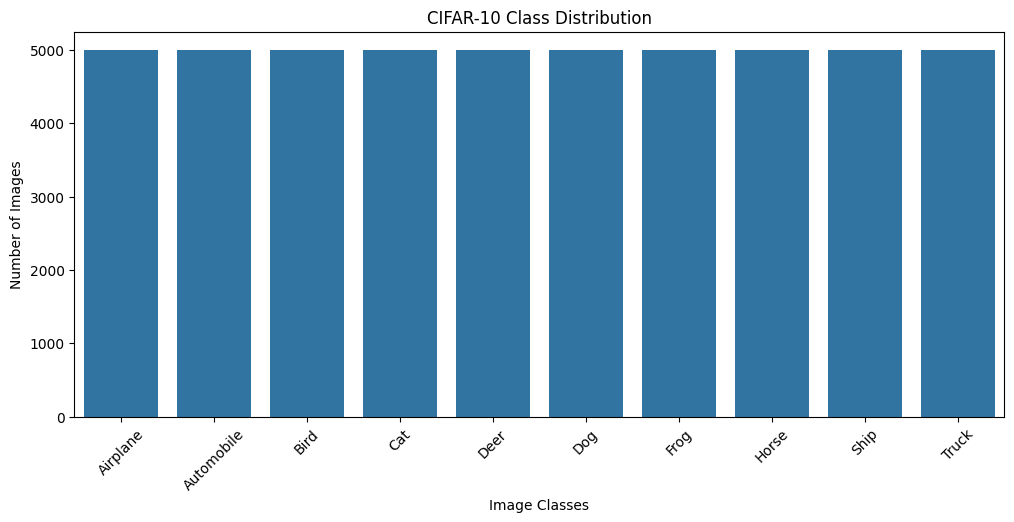

In [7]:
plt.figure(figsize=(12,5))

sns.barplot(
    x='Class',
    y='Image Count',
    data=distribution
)

plt.title("CIFAR-10 Class Distribution")
plt.xlabel("Image Classes")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)

plt.show()

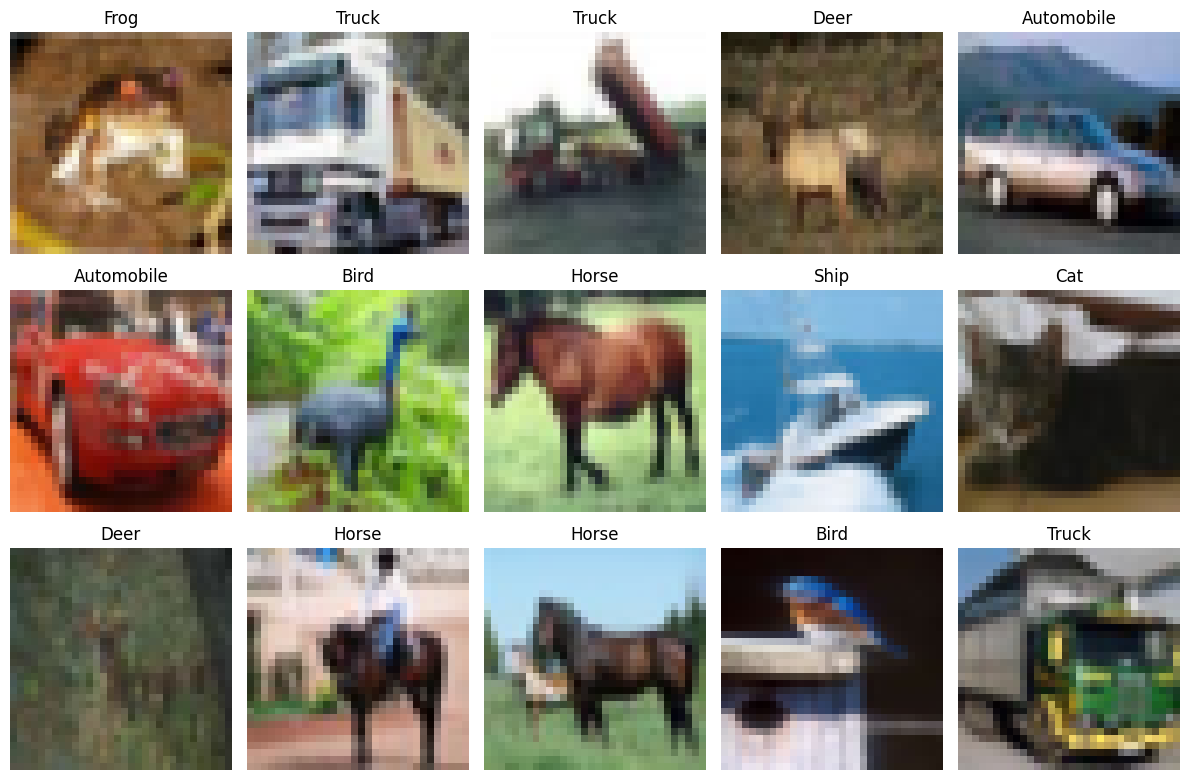

In [8]:
plt.figure(figsize=(12,8))

for i in range(15):
    plt.subplot(3,5,i+1)

    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i][0]])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [9]:
import cv2

brightness_values = []
blur_values = []
width_values = []
height_values = []

for img in x_train:

    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

    brightness = np.mean(gray)

    blur = cv2.Laplacian(
        gray, cv2.CV_64F
    ).var()

    height, width = img.shape[:2]

    brightness_values.append(brightness)
    blur_values.append(blur)
    width_values.append(width)
    height_values.append(height)

print("Image Quality Analysis Completed!")

Image Quality Analysis Completed!


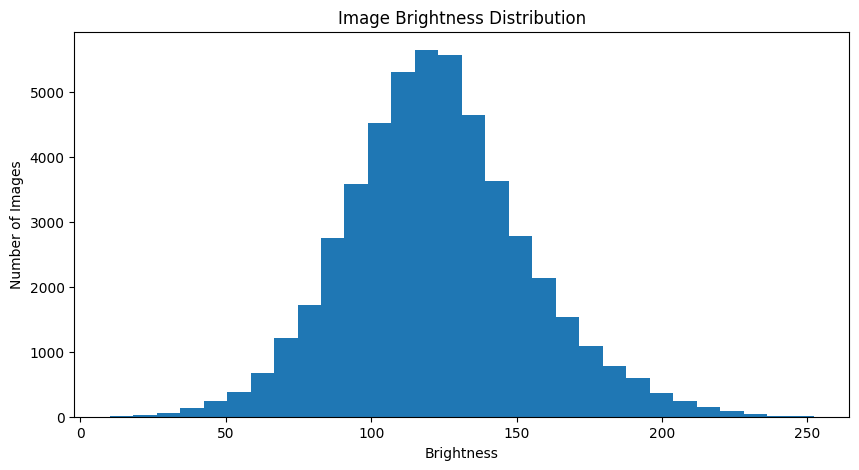

In [10]:
plt.figure(figsize=(10,5))

plt.hist(brightness_values, bins=30)

plt.title("Image Brightness Distribution")
plt.xlabel("Brightness")
plt.ylabel("Number of Images")

plt.show()

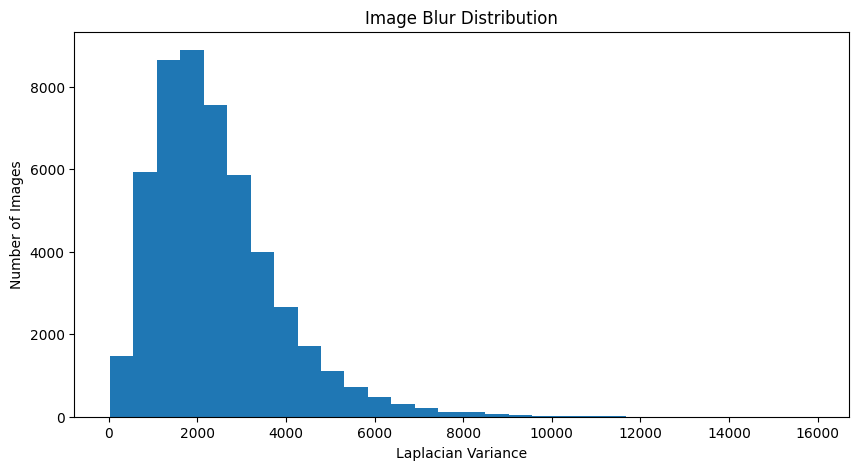

In [11]:
plt.figure(figsize=(10,5))

plt.hist(blur_values, bins=30)

plt.title("Image Blur Distribution")
plt.xlabel("Laplacian Variance")
plt.ylabel("Number of Images")

plt.show()

In [12]:
print("Image Width:", set(width_values))
print("Image Height:", set(height_values))

print("Total Images:", len(x_train))

print("Images with incorrect dimensions:",
      sum(w != 32 or h != 32
          for w, h in zip(width_values, height_values)))

Image Width: {32}
Image Height: {32}
Total Images: 50000
Images with incorrect dimensions: 0


In [13]:
labels = y_train.flatten()

invalid_labels = np.sum(
    (labels < 0) | (labels >= len(class_names))
)

missing_labels = np.isnan(labels).sum()

print("Total Annotations:", len(labels))
print("Invalid Labels:", invalid_labels)
print("Missing Labels:", missing_labels)

if invalid_labels == 0 and missing_labels == 0:
    print("All annotations are valid!")
else:
    print("Annotation errors found!")

Total Annotations: 50000
Invalid Labels: 0
Missing Labels: 0
All annotations are valid!


In [14]:
print("======================================")
print("       DATASET AUDIT REPORT")
print("======================================")

print("Dataset Name: CIFAR-10")
print("Training Images:", len(x_train))
print("Testing Images:", len(x_test))
print("Total Classes:", len(class_names))

print("\nClass Distribution:")
print(distribution.to_string(index=False))

print("\nImage Quality:")
print("Average Brightness:",
      round(np.mean(brightness_values), 2))

print("Average Blur Score:",
      round(np.mean(blur_values), 2))

print("\nImage Dimensions: 32 x 32")

print("\nAnnotation Validation:")
print("Invalid Labels:", invalid_labels)
print("Missing Labels:", missing_labels)

print("\nDATASET AUDIT COMPLETED SUCCESSFULLY!")
print("======================================")

       DATASET AUDIT REPORT
Dataset Name: CIFAR-10
Training Images: 50000
Testing Images: 10000
Total Classes: 10

Class Distribution:
     Class  Image Count
  Airplane         5000
Automobile         5000
      Bird         5000
       Cat         5000
      Deer         5000
       Dog         5000
      Frog         5000
     Horse         5000
      Ship         5000
     Truck         5000

Image Quality:
Average Brightness: 122.62
Average Blur Score: 2416.25

Image Dimensions: 32 x 32

Annotation Validation:
Invalid Labels: 0
Missing Labels: 0

DATASET AUDIT COMPLETED SUCCESSFULLY!
